# Projet IMA - Exposure Fusion

Adam Safieddine, Victor Coulet

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 70

In [2]:
#lecture d'une image en float entre 0 et 1, on la reduit car les photos font 6720x4480
def charger(chemin, largeur=1200):
    img = cv2.imread(chemin)
    h, w = img.shape[:2]
    img = cv2.resize(img, (largeur, int(h * largeur / w)), interpolation=cv2.INTER_AREA)
    return img.astype(np.float32) / 255.0

#affichage avec matplotlib (opencv est en BGR)
def afficher(img, titre="", ax=None):
    if ax is None:
        plt.figure(figsize=(8, 5))
        ax = plt.gca()
    if img.ndim == 3:
        ax.imshow(cv2.cvtColor(np.clip(img, 0, 1).astype(np.float32), cv2.COLOR_BGR2RGB))
    else:
        ax.imshow(img, cmap="gray")
    ax.set_title(titre)
    ax.axis("off")

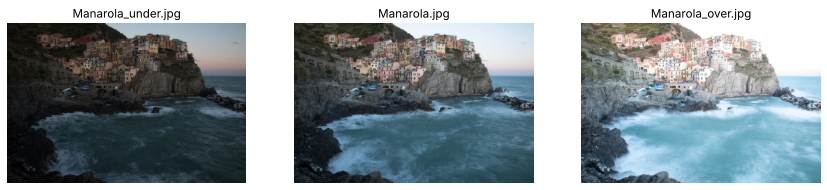

In [3]:
dossier = "Cinque-Terre-Manarola/"
noms = ["Manarola_under.jpg", "Manarola.jpg", "Manarola_over.jpg"]
images = [charger(dossier + n) for n in noms]

fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for img, n, ax in zip(images, noms, axs):
    afficher(img, n, ax)
plt.show()

## 1. Pyramide gaussienne

G(l+1) = sous-echantillonnage par 2 de flou(G(l))

In [4]:
#pyramide gaussienne
def pyramide_gauss(img, niveaux):
    G = [img]
    for i in range(niveaux - 1):
        G.append(cv2.pyrDown(G[-1]))
    return G

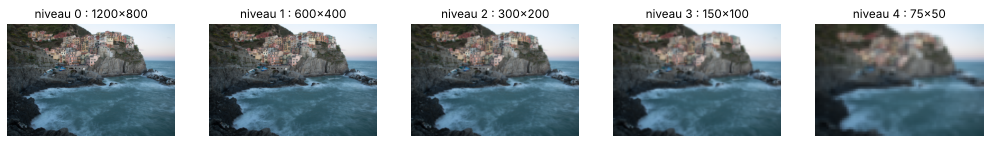

In [5]:
img = images[1]
G = pyramide_gauss(img, 5)

fig, axs = plt.subplots(1, 5, figsize=(18, 3))
for i, g in enumerate(G):
    afficher(g, f"niveau {i} : {g.shape[1]}x{g.shape[0]}", axs[i])
plt.show()

## 2. Pyramide laplacienne

L(l) = G(l) - Pyrup(G(l+1)) et L(N) = G(N)

In [6]:
#pyramide laplacienne
def pyramide_laplace(img, niveaux):
    G = pyramide_gauss(img.astype(np.float32), niveaux)
    L = []
    for i in range(niveaux - 1):
        taille = (G[i].shape[1], G[i].shape[0])
        L.append(G[i] - cv2.pyrUp(G[i + 1], dstsize=taille))
    L.append(G[-1])
    return L

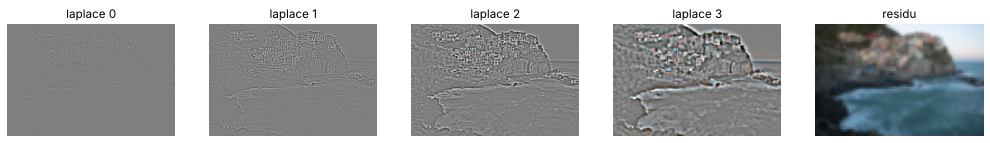

In [7]:
L = pyramide_laplace(img, 5)

fig, axs = plt.subplots(1, 5, figsize=(18, 3))
for i, l in enumerate(L[:-1]):
    afficher(np.clip(l * 3 + 0.5, 0, 1), f"laplace {i}", axs[i])
afficher(L[-1], "residu", axs[4])
plt.show()

## 3. Reconstruction

G(l) = L(l) + Pyrup(G(l+1))

In [8]:
#reconstruction a partir de la pyramide laplacienne
def reconstruction(L):
    img = L[-1]
    for niv in reversed(L[:-1]):
        taille = (niv.shape[1], niv.shape[0])
        img = cv2.pyrUp(img, dstsize=taille) + niv
    return img

In [9]:
rec = reconstruction(L)
print("erreur max :", np.abs(rec - img).max())

erreur max : 5.9604645e-08


## 4. Cartes de poids

W = C^wc * S^ws * E^we, puis normalisation sur les images

In [10]:
#contraste sur l'image en niveaux de gris
def contraste(img):
    gris = cv2.cvtColor(img.astype(np.float32), cv2.COLOR_BGR2GRAY)
    return np.abs(cv2.Laplacian(gris, cv2.CV_32F))

#saturation = ecart type sur les 3 canaux
def saturation(img):
    return np.std(img, axis=2)

#bonne exposition, proche de 0.5
def exposition(img, sigma=0.2):
    g = np.exp(-((img - 0.5) ** 2) / (2 * sigma ** 2))
    return np.prod(g, axis=2)

In [11]:
#carte de poids d'une image
def carte_poids(img, wc=1, ws=1, we=1):
    return (contraste(img) ** wc) * (saturation(img) ** ws) * (exposition(img) ** we)

#normalisation des poids sur toutes les images
def poids_normalises(images, wc=1, ws=1, we=1, eps=1e-12):
    W = np.array([carte_poids(im, wc, ws, we) for im in images]) + eps
    return W / W.sum(axis=0)

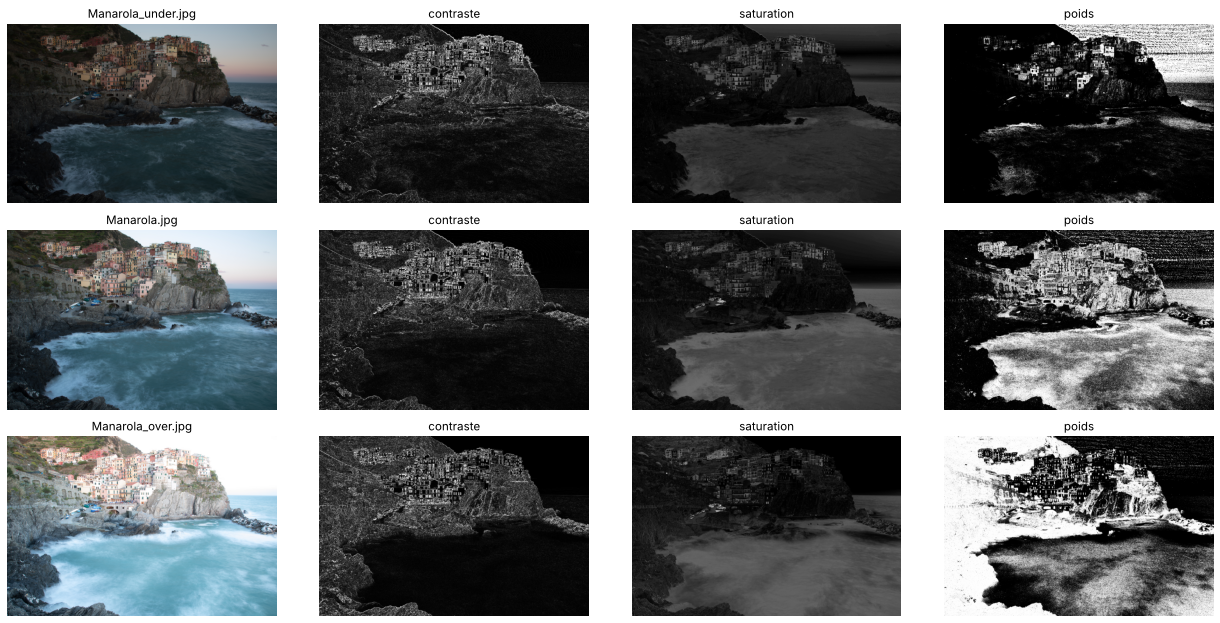

In [12]:
W = poids_normalises(images)

fig, axs = plt.subplots(3, 4, figsize=(18, 9))
for k, (im, n) in enumerate(zip(images, noms)):
    c = contraste(im)
    afficher(im, n, axs[k, 0])
    afficher(np.clip(c / np.percentile(c, 99), 0, 1), "contraste", axs[k, 1])
    afficher(saturation(im) / saturation(im).max(), "saturation", axs[k, 2])
    afficher(W[k], "poids", axs[k, 3])
plt.tight_layout()
plt.show()

## 5. Fusion naive

R = somme sur k de W_k * I_k

In [13]:
#fusion naive, moyenne ponderee des images
def fusion_naive(images, W):
    R = np.zeros_like(images[0])
    for im, w in zip(images, W):
        R += w[..., None] * im
    return R

## 6. Fusion multiresolution

L_R(l) = somme sur k de G{W_k}(l) * L{I_k}(l)

In [14]:
#fusion multiresolution avec les pyramides
def fusion_pyramide(images, W, niveaux=7):
    LR = None
    for im, w in zip(images, W):
        L = pyramide_laplace(im, niveaux)
        Gw = pyramide_gauss(w.astype(np.float32), niveaux)
        if LR is None:
            LR = [np.zeros_like(l) for l in L]
        for l in range(niveaux):
            LR[l] += Gw[l][..., None] * L[l]
    return reconstruction(LR)

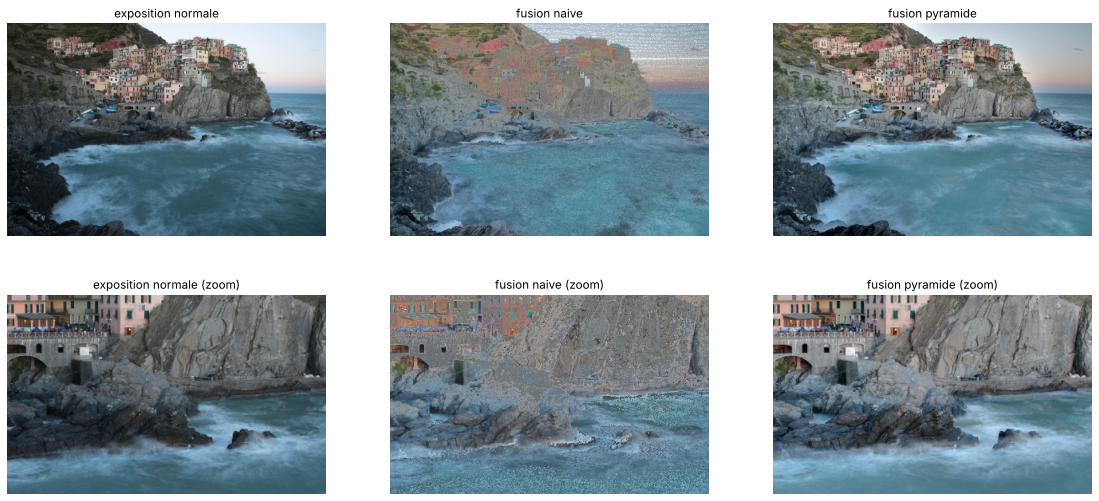

In [15]:
R = fusion_naive(images, W)
R_pyr = fusion_pyramide(images, W)

y, x = 250, 450
fig, axs = plt.subplots(2, 3, figsize=(20, 9))
for j, (im, t) in enumerate([(images[1], "exposition normale"), (R, "fusion naive"), (R_pyr, "fusion pyramide")]):
    afficher(im, t, axs[0, j])
    afficher(im[y:y+250, x:x+400], t + " (zoom)", axs[1, j])
plt.show()

## 7. Autres scenes

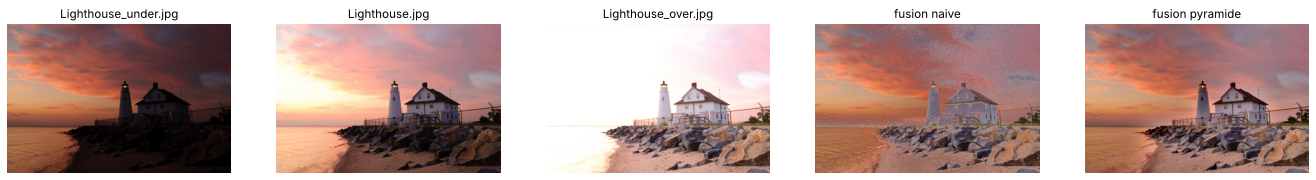

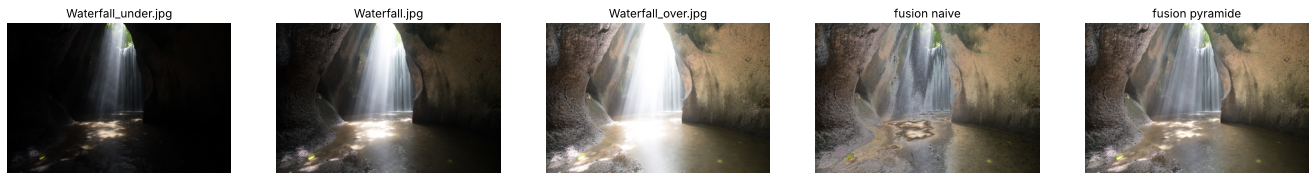

In [16]:
for dossier, noms_s in [("Cove-Point-Lighthouse/", ["Lighthouse_under.jpg", "Lighthouse.jpg", "Lighthouse_over.jpg"]),
                       ("Bali-Tukad-Cepung-Waterfall/", ["Waterfall_under.jpg", "Waterfall.jpg", "Waterfall_over.jpg"])]:
    ims = [charger(dossier + n) for n in noms_s]
    fig, axs = plt.subplots(1, 5, figsize=(24, 4))
    for im, n, ax in zip(ims, noms_s, axs):
        afficher(im, n, ax)
    Wk = poids_normalises(ims)
    afficher(fusion_naive(ims, Wk), "fusion naive", axs[3])
    afficher(fusion_pyramide(ims, Wk), "fusion pyramide", axs[4])
    plt.show()